# Linear Regression for Stellar Spectra

*Tutorial by Yuan-Sen Ting (ting.74@osu.edu)*

*Companion material for Chapter 4 of the textbook*

*If you find this tutorial useful, please cite the accompanying textbook.*

*[Statistical Machine Learning for Astronomy](https://ui.adsabs.harvard.edu/abs/2025arXiv250612230T/abstract)*

*© 2025 Yuan-Sen Ting. All rights reserved. This tutorial may be redistributed by sharing the original [website page link](https://statml.org/) for educational purposes. Any other reproduction or adaptation requires explicit permission from the author.*

## Introduction

In Chapter 3 we described distributions with summary statistics and studied the uncertainty of our measurements. We now turn to linear regression, one of the basic techniques that predict a quantity from data. Linear regression is simple, and it helps us to understand more complex machine learning methods. Many sophisticated algorithms build on it.

This tutorial applies linear regression to an astronomical problem, the prediction of the effective temperature of a star from its spectrum. We use data from the Apache Point Observatory Galactic Evolution Experiment (APOGEE), part of the Sloan Digital Sky Survey. APOGEE has obtained high-resolution infrared spectra for hundreds of thousands of stars. The spectra give the chemical compositions, temperatures and kinematics of the stars, and they have improved our understanding of the Milky Way.

Deriving physical parameters from stellar spectra is a central problem of modern astronomy. A spectrum carries a lot of information about the atmosphere of a star. The temperature sets the overall energy distribution and the ionization states. A higher surface gravity gives a higher gas pressure in the atmosphere, which widens the spectral lines. The chemical abundances appear as absorption features at specific wavelengths. Linear regression can turn thousands of flux measurements into physical parameters.

The application also shows concepts of machine learning. We see how maximum likelihood estimation gives an analytical solution for linear regression. We study regularization, which limits overfitting, and we test whether feature engineering helps the predictions. These concepts apply to any problem that predicts a continuous quantity from high-dimensional data.

Linear regression is also easy to interpret. Many modern machine learning methods act as black boxes, but a linear model gives a transparent relation between the inputs and the output. The weights can hint at which spectral regions carry information about the temperature.

## Prerequisites and Learning Objectives

### Prerequisites

This tutorial assumes the following.

- Linear algebra, with matrix operations, transposes and inverses, which the solution of linear regression uses
- Probability theory, in particular Gaussian distributions and the likelihood
- Maximum likelihood estimation, the principle of finding the parameters that make the observed data most probable
- Python programming, with NumPy arrays and matplotlib plots

### Learning Objectives

After this tutorial you can do the following.

- Explain how stellar spectra encode physical information and how a linear regression model can extract it
- Implement the maximum likelihood solution of linear regression for high-dimensional data
- Apply regularization to reduce overfitting and improve generalization
- Use basis functions, here quadratic features, to model nonlinear relations with a model that is linear in its weights
- Evaluate a model with training, validation and test sets

We begin by importing the libraries and setting the plot style.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline

# Set the plot style
plt.rcParams['figure.figsize'] = [10, 6]
plt.rcParams['font.size'] = 15
plt.rcParams['axes.labelsize'] = 15
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['xtick.labelsize'] = 15
plt.rcParams['ytick.labelsize'] = 15
plt.rcParams['legend.fontsize'] = 15
plt.rcParams['legend.frameon'] = False
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=['#3468A8', '#E49A3A', '#2E8B6E', '#C24A3E', '#6F5E9E', '#8A8A8A'])
plt.rcParams.update({'font.family': 'serif', 'font.serif': ['DejaVu Serif'], 'mathtext.fontset': 'cm'})
plt.rcParams.update({'xtick.direction': 'in', 'ytick.direction': 'in', 'xtick.top': True, 'ytick.right': True})

# Fix the random seed
np.random.seed(42)

## The APOGEE Dataset

APOGEE is a large stellar spectroscopic survey. It observes in the near-infrared H band (1.5 to 1.7 $\mu$m), where dust absorbs less light than in the optical. APOGEE can therefore see stars in the disk, the bulge and the halo of the Milky Way. Each APOGEE spectrum has thousands of absorption lines that carry information about the atmosphere of the star.

We use a subset of 3,000 spectra from APOGEE Data Release 17 (DR17), with a signal-to-noise ratio (SNR) above 100. The high SNR makes the noise in the fluxes, the inputs of our model, small. We choose the stars at random among those with clean spectra. One third are dwarfs and two thirds are giants.

Full APOGEE spectra have more than 7,000 pixels. We truncate each spectrum to 2,000 pixels. This keeps enough spectral information to predict the temperature and keeps the computation short. The concepts of this tutorial stay the same for 2,000 or 7,000 features. Fewer pixels let us focus on the method.

### Physical Parameters

The APOGEE spectroscopic pipeline gives many parameters for each star. The three main stellar parameters of a spectrum are usually the following.

1. **Effective temperature ($T_{\rm eff}$)** is the temperature of a black body that emits the same power per unit surface area as the star. It sets the overall energy distribution and the ionization states of the elements in the atmosphere. We use it as the target of the regression.
2. **Surface gravity (log g)** is the logarithm of the gravitational acceleration at the surface in cgs units. It separates dwarfs (high gravity) from giants (low gravity) and changes the pressure broadening of the spectral lines.
3. **Metallicity ([Fe/H])** is the base-10 logarithm of the iron to hydrogen number ratio of the star, relative to the Sun. A star with [Fe/H] = -1 has an iron to hydrogen ratio ten times lower than the Sun. It traces the chemical enrichment history of the gas that formed the star.

The pipeline gives the temperatures that we predict, so the errors below measure the agreement with the pipeline. We treat the noise of these target temperatures as uniform (homoscedastic), a simplification that lets us focus on the core concepts of linear regression. Real spectra also have a measurement uncertainty at each wavelength, which is noise in the inputs. The SNR cut makes it small, so we assume that it is negligible.

We now load the dataset.

In [2]:
# Load the APOGEE spectra and the pipeline parameters
data = np.load('../data/dataset_apogee_spectra.npz')

# Extract the arrays
spectra = data['spectrum_array']
wavelength = data['wavelength']
teff_array = data['teff_array']
logg_array = data['logg_array']
feh_array = data['feh_array']

# Print the basic properties of the dataset
print("Dataset overview")
print(f"Number of stars = {len(spectra)}")
print(f"Spectral pixels per star = {len(wavelength)}")
print(f"Wavelength range = {wavelength[0]:.1f} - {wavelength[-1]:.1f} Å")
print("\nRanges of the stellar parameters")
print(f"Temperature = {np.min(teff_array):.0f} - {np.max(teff_array):.0f} K")
print(f"Surface gravity = {np.min(logg_array):.2f} - {np.max(logg_array):.2f} dex")
print(f"Metallicity = {np.min(feh_array):.2f} - {np.max(feh_array):.2f} dex")

Dataset overview
Number of stars = 3000
Spectral pixels per star = 2000
Wavelength range = 15168.1 - 15592.9 Å

Ranges of the stellar parameters
Temperature = 3585 - 6433 K
Surface gravity = 0.07 - 4.76 dex
Metallicity = -2.41 - 0.42 dex


## Visualizing Stellar Spectra

Before the regression, we look at what stellar spectra are like and how they change with temperature. A spectrum has many absorption features, which are dark lines where atoms and molecules in the stellar atmosphere absorb light at specific wavelengths. The strength of these features depends on the physical parameters of the star.

We compare the spectra of stars with different effective temperatures. This comparison shows why linear regression can extract the temperature, because different temperatures give different spectra. Cooler stars usually have deeper absorption features, both atomic lines and molecular bands. Hotter stars have shallower but still characteristic absorption. These systematic changes with temperature are the signal that the regression model learns to use.

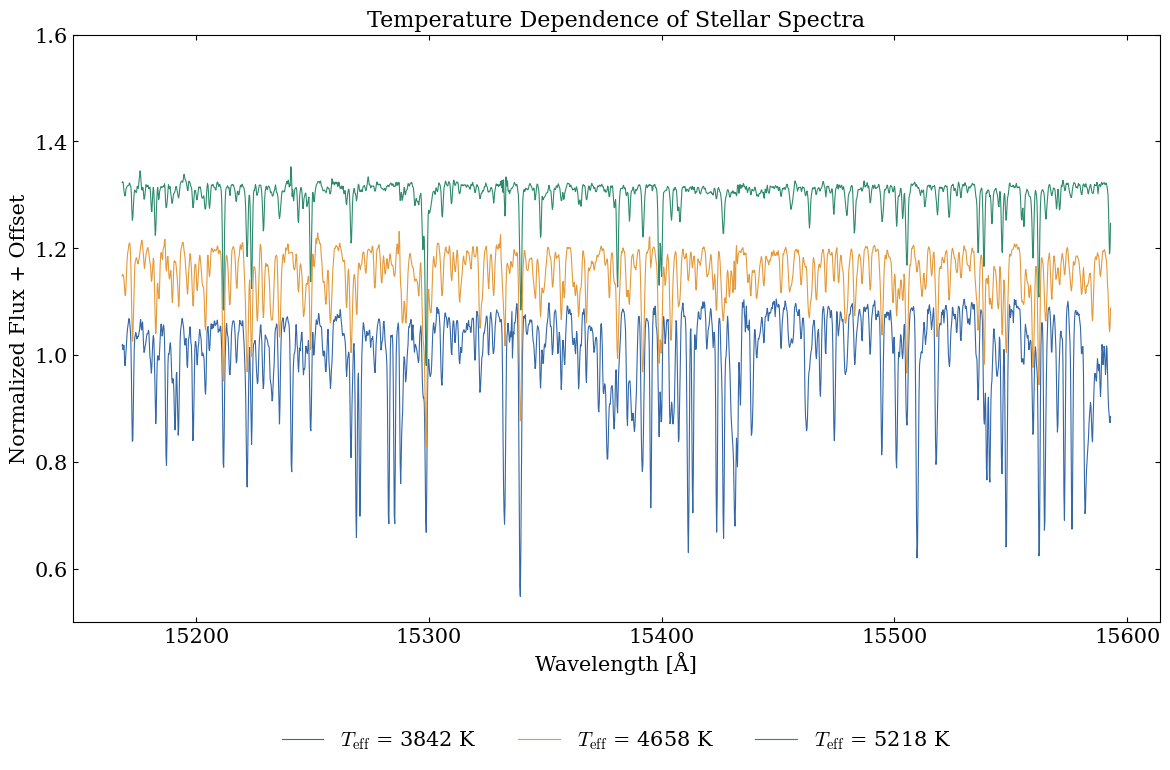

In [3]:
# Select stars with different temperatures for comparison
# Find the first star in each of three temperature ranges
temp_ranges = [(3800, 4000), (4500, 4700), (5200, 5400)]
selected_indices = []
selected_temps = []

for t_min, t_max in temp_ranges:
    # Mask of the stars inside the range
    mask = (teff_array >= t_min) & (teff_array <= t_max)
    if np.any(mask):
        # Index of the first star in the range
        idx = np.where(mask)[0][0]
        selected_indices.append(idx)
        selected_temps.append(teff_array[idx])

# Plot the spectra at different temperatures
plt.figure(figsize=(12, 8))

# Plot the full spectra with an offset for clarity
for i, (idx, temp) in enumerate(zip(selected_indices, selected_temps)):
    offset = i * 0.15  # Vertical offset for clarity
    plt.plot(wavelength, spectra[idx] + offset, linewidth=0.8,
             label=rf'$T_{{\rm eff}}$ = {temp:.0f} K')

plt.xlabel('Wavelength [Å]')
plt.ylabel('Normalized Flux + Offset')
plt.title('Temperature Dependence of Stellar Spectra')
plt.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.15))
plt.ylim(0.5, 1.6)

plt.tight_layout()
plt.show()

## The Kiel Diagram

We also look at the distribution of the stellar parameters in our sample. The Kiel diagram, a plot of surface gravity against effective temperature, shows the evolutionary states of the stars. Different regions of the diagram belong to different types of stars. Dwarfs (main sequence stars) have high surface gravity, and red giants have lower gravity and cooler temperatures. The color shows the metallicity, which adds a third parameter and shows how the chemical composition varies in the diagram.

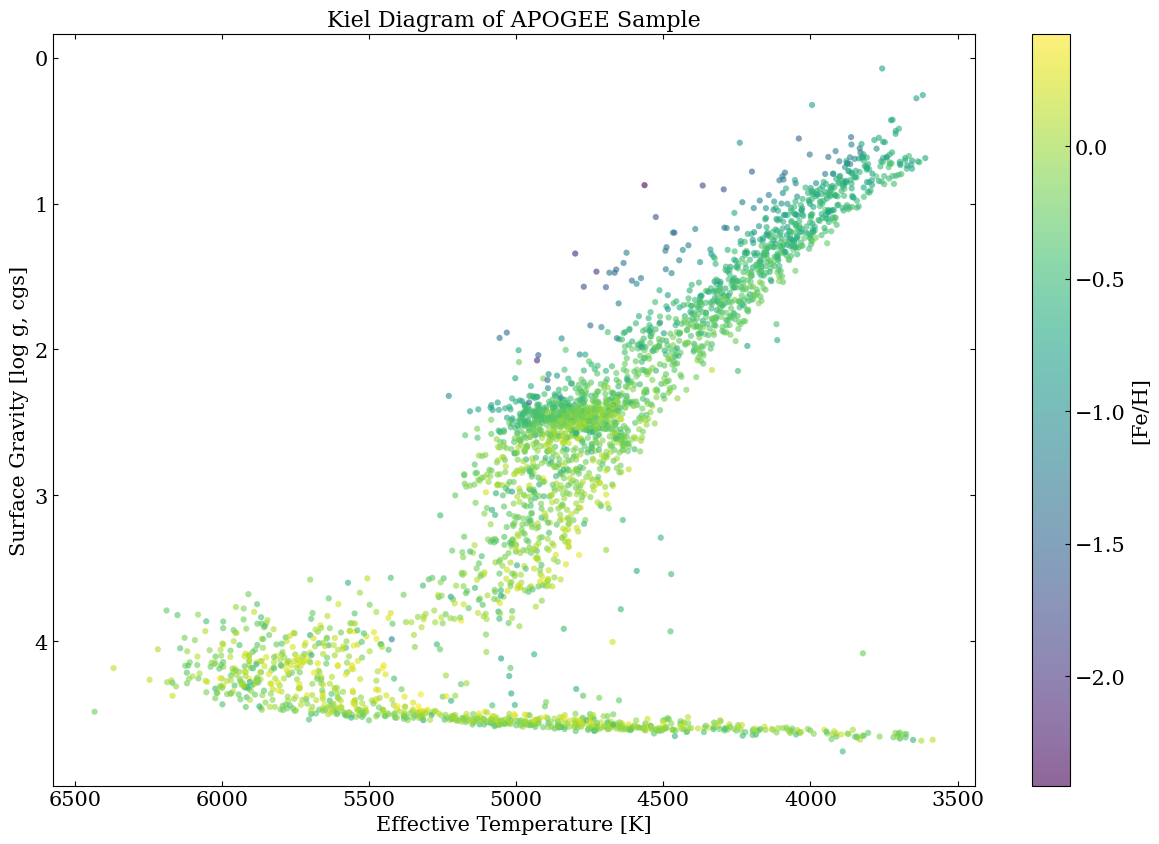

Parameter space coverage
Temperature = 3585 - 6433 K (Δ = 2848 K)
Surface gravity = 0.07 - 4.76 dex (Δ = 4.68 dex)
Metallicity = -2.41 - 0.42 dex (Δ = 2.83 dex)


In [4]:
# Create the Kiel diagram
plt.figure(figsize=(12.4, 8.7))

scatter = plt.scatter(teff_array, logg_array, c=feh_array,
                      cmap='viridis', s=20, alpha=0.6, edgecolors='none')

# Customize the plot
plt.xlabel('Effective Temperature [K]')
plt.ylabel('Surface Gravity [log g, cgs]')
plt.title('Kiel Diagram of APOGEE Sample')
plt.colorbar(scatter, label='[Fe/H]')

# Invert the axes, as is usual in astronomy
plt.gca().invert_xaxis()  # Hot stars on the left
plt.gca().invert_yaxis()  # High gravity at the bottom


plt.tight_layout()
plt.show()

# Analyze the parameter distributions
print("Parameter space coverage")
print(f"Temperature = {np.min(teff_array):.0f} - {np.max(teff_array):.0f} K "
      f"(Δ = {np.max(teff_array) - np.min(teff_array):.0f} K)")
print(f"Surface gravity = {np.min(logg_array):.2f} - {np.max(logg_array):.2f} dex "
      f"(Δ = {np.max(logg_array) - np.min(logg_array):.2f} dex)")
print(f"Metallicity = {np.min(feh_array):.2f} - {np.max(feh_array):.2f} dex "
      f"(Δ = {np.max(feh_array) - np.min(feh_array):.2f} dex)")

The sample covers both groups of stars. The main sequence of dwarfs lies at high gravity, and the red giant branch lies at low gravity. The dense group near $\log g = 2.5$ and 4800 K is the red clump, which holds giants that burn helium in their cores.

This distribution matters for the interpretation of the regression results. The model is most reliable where the sample is dense, for temperatures between 3500 and 5500 K. Predictions for hotter stars need care, because the model has few examples of them.

## Linear Regression: Setting Up the Model

With the data explored, we turn to the core task, the prediction of the effective temperature from the spectrum. Linear regression models the relation between the input features, the flux values of the spectrum, and the target, the effective temperature, as a linear combination

$$T_{\rm eff} = \sum_{j=1}^{D} w_j \phi_j + w_0,$$

where $D$ is the number of pixels and $\phi_j$ is the flux at the $j$th wavelength. The weights $w_j$ are what we learn, and $w_0$ is the bias term.

To simplify the notation and the computation, we absorb the bias term into the weight vector. We append a column of ones to the design matrix $\boldsymbol{\Phi}$, and the model becomes

$$\mathbf{t} \approx \boldsymbol{\Phi}\mathbf{w},$$

where $\boldsymbol{\Phi}$ now holds the spectral features and the column of ones, and $\mathbf{w}$ holds all weights including the bias. The bias is one more parameter, so no step of the computation needs a special rule.

We now build $\boldsymbol{\Phi}$ from the spectra and keep 20 percent of the stars as test stars. The training stars fit the weights. The test stars show how well the model predicts stars that it has not seen.

In [5]:
# Prepare the data for linear regression
# Use the spectra as the design matrix Phi
Phi = spectra.copy()

# Add the bias term by appending a column of ones
Phi = np.hstack((Phi, np.ones((Phi.shape[0], 1))))
print(f"Design matrix shape = {Phi.shape}")
print(f"({spectra.shape[0]} spectra x {spectra.shape[1]} spectral pixels + 1 bias term)")

# Use the effective temperature as the target variable
t = teff_array
print(f"\nTarget variable shape = {t.shape}")
print(f"Temperature range = {t.min():.0f} - {t.max():.0f} K")

# Split the stars into 60 percent fit stars, 20 percent validation stars and 20 percent test stars
# This is the same as two splits, first 80 percent training and 20 percent test stars,
# and then 75 percent fit and 25 percent validation stars among the training stars
def split_indices(n, test_size, random_state):
    """Return the indices of the training and the test stars of a random split."""
    n_test = int(np.ceil(test_size * n))
    permutation = np.random.RandomState(random_state).permutation(n)
    return permutation[n_test:], permutation[:n_test]

train_index, test_index = split_indices(len(t), 0.2, 42)
Phi_train, Phi_test = Phi[train_index], Phi[test_index]
t_train, t_test = t[train_index], t[test_index]

print(f"\nTraining set = {Phi_train.shape[0]} spectra")
print(f"Test set = {Phi_test.shape[0]} spectra")

Design matrix shape = (3000, 2001)
(3000 spectra x 2000 spectral pixels + 1 bias term)

Target variable shape = (3000,)
Temperature range = 3585 - 6433 K

Training set = 2400 spectra
Test set = 600 spectra


## Maximum Likelihood Estimation for Linear Regression

The principle of maximum likelihood is a systematic way to find the best model parameters. We assume Gaussian noise with a constant variance $\sigma^2$. The likelihood of the data for the parameters $\mathbf{w}$ is

$$p(\mathbf{t}|\boldsymbol{\Phi}, \mathbf{w}, \sigma^2) = \prod_{i=1}^{N} \mathcal{N}(t_i | \mathbf{w}^T\boldsymbol{\phi}_i, \sigma^2),$$

where $N$ is the number of training stars and $\boldsymbol{\phi}_i$ is the $i$th row of $\boldsymbol{\Phi}$.

Maximizing the likelihood, or equivalently minimizing the negative log-likelihood, gives the familiar least-squares objective. As Section 4.4 of the textbook shows, this optimization has an analytical solution

$$\mathbf{w}_{\text{ML}} = (\boldsymbol{\Phi}^T \boldsymbol{\Phi})^{-1} \boldsymbol{\Phi}^T \mathbf{t}.$$

This closed-form solution is an advantage of linear regression, because we can find the globally optimal parameters without iterative optimization. It needs only matrix operations. We compute the matrix $\boldsymbol{\Phi}^T \boldsymbol{\Phi}$, invert it and multiply. We now implement the solution and compute the root mean squared error (RMSE) of the predicted temperatures on the training and test stars.

Maximum likelihood fit
Training RMSE = 28.7 K
Test RMSE = 279.5 K


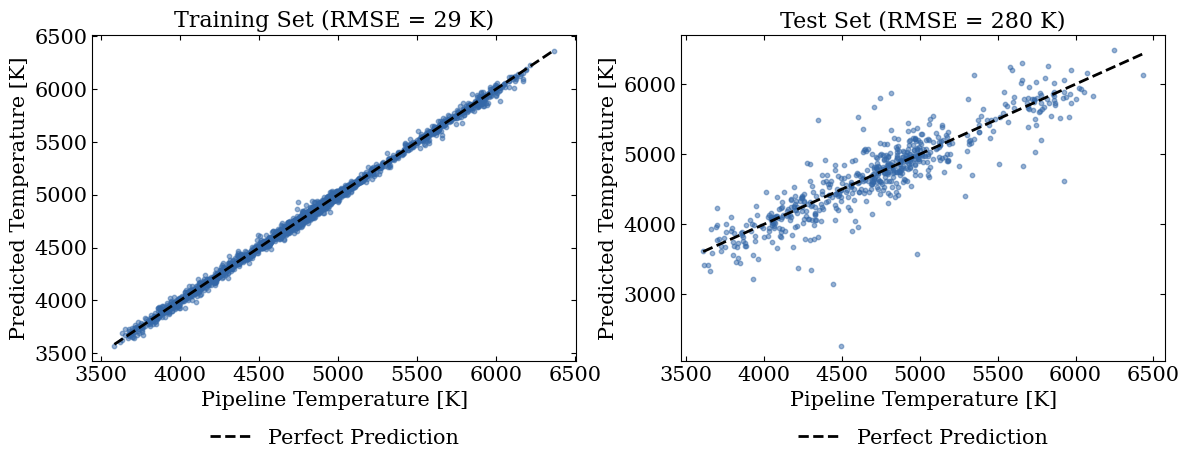

In [6]:
# Compute the maximum likelihood weights with the analytical solution
# np.linalg.lstsq is more stable for high-dimensional data, but the direct formula shows the algebra
w_ml = np.linalg.inv(Phi_train.T @ Phi_train) @ Phi_train.T @ t_train

# Make predictions on the training and test sets
t_pred_train = Phi_train @ w_ml
t_pred_test = Phi_test @ w_ml

# Calculate the root mean squared error (RMSE)
train_rmse_ml = np.sqrt(np.mean((t_train - t_pred_train)**2))
test_rmse_ml = np.sqrt(np.mean((t_test - t_pred_test)**2))

print("Maximum likelihood fit")
print(f"Training RMSE = {train_rmse_ml:.1f} K")
print(f"Test RMSE = {test_rmse_ml:.1f} K")

# Visualize the predictions against the pipeline temperatures
plt.figure(figsize=(12, 5))

# Training set
plt.subplot(1, 2, 1)
plt.scatter(t_train, t_pred_train, alpha=0.5, s=10)
plt.plot([t_train.min(), t_train.max()], [t_train.min(), t_train.max()],
         'k--', lw=2, label='Perfect Prediction')
plt.xlabel('Pipeline Temperature [K]')
plt.ylabel('Predicted Temperature [K]')
plt.title(f'Training Set (RMSE = {train_rmse_ml:.0f} K)')
plt.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.15))

# Test set
plt.subplot(1, 2, 2)
plt.scatter(t_test, t_pred_test, alpha=0.5, s=10)
plt.plot([t_test.min(), t_test.max()], [t_test.min(), t_test.max()],
         'k--', lw=2, label='Perfect Prediction')
plt.xlabel('Pipeline Temperature [K]')
plt.ylabel('Predicted Temperature [K]')
plt.title(f'Test Set (RMSE = {test_rmse_ml:.0f} K)')
plt.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.15))

plt.tight_layout()
plt.show()

The training RMSE is about 30 K, so the model fits the training stars very well. The test RMSE is about 280 K, so the model fails on stars that it has not seen.

This is a typical case of overfitting. The model has memorized the training spectra and has not learned a relation that generalizes. The count of the parameters explains this. We fit 2,001 parameters (2,000 spectral features and the bias) with only 2,400 training stars. When the number of parameters approaches the number of training stars, the model can reproduce the training data almost perfectly. It also learns spurious relations that do not generalize.

This large increase of the error shows that the unregularized model does not learn the true relation between the spectra and the temperature. It fits the noise and the peculiarities of the training stars.

## Regularization: Preventing Overfitting

Regularization limits overfitting. It constrains the model to prefer simpler solutions that generalize better. We can interpret regularization in a Bayesian way. A zero-mean Gaussian prior with variance $\eta^2$ on the weights is equivalent to adding a penalty to the objective function. The penalty is $\lambda$ times the sum of the squared weights.

The regularized solution is

$$\mathbf{w}_{\text{reg}} = (\lambda \mathrm{Id} + \boldsymbol{\Phi}^T\boldsymbol{\Phi})^{-1}\boldsymbol{\Phi}^T\mathbf{t},$$

where $\mathrm{Id}$ is the identity matrix and $\lambda = \sigma^2/\eta^2$ is the regularization parameter that sets the strength of the penalty. A larger $\lambda$ constrains the weights more, so the model fits less of the noise in the training data.

We choose $\lambda$ on validation stars and not on the test stars. The test stars then stay an unbiased check (Section 4.7 of the textbook). The split is 60 percent fit stars, 20 percent validation stars and 20 percent test stars. For each $\lambda$ we fit the fit stars and evaluate on the validation stars.

In [7]:
# Define the function for regularized linear regression
def compute_regularized_weights(Phi_train, t_train, lambda_reg):
    """Compute the regularized weights for the regularization parameter lambda_reg."""
    n_features = Phi_train.shape[1]
    I = np.eye(n_features)  # Identity matrix

    # Regularized solution (lambda I + Phi^T Phi)^-1 Phi^T t
    w = np.linalg.inv(lambda_reg * I + Phi_train.T @ Phi_train) @ Phi_train.T @ t_train
    return w

# Second split, of the training stars into 75 percent fit stars and 25 percent validation stars
fit_index, val_index = split_indices(len(t_train), 0.25, 42)
Phi_fit, Phi_val = Phi_train[fit_index], Phi_train[val_index]
t_fit, t_val = t_train[fit_index], t_train[val_index]

# Explore a range of regularization parameters, fitting the fit stars only
lambda_values = np.logspace(-3, 2, 20)  # From 0.001 to 100
results = []

for lambda_reg in lambda_values:
    # Compute the regularized weights
    w_reg = compute_regularized_weights(Phi_fit, t_fit, lambda_reg)

    # Compute the predictions
    t_pred_fit = Phi_fit @ w_reg
    t_pred_val = Phi_val @ w_reg

    # Compute the RMSE
    fit_rmse = np.sqrt(np.mean((t_fit - t_pred_fit)**2))
    val_rmse = np.sqrt(np.mean((t_val - t_pred_val)**2))

    results.append({
        'lambda': lambda_reg,
        'fit_rmse': fit_rmse,
        'val_rmse': val_rmse
    })

We plot the fit and the validation RMSE against $\lambda$, and we find the value with the lowest validation RMSE.

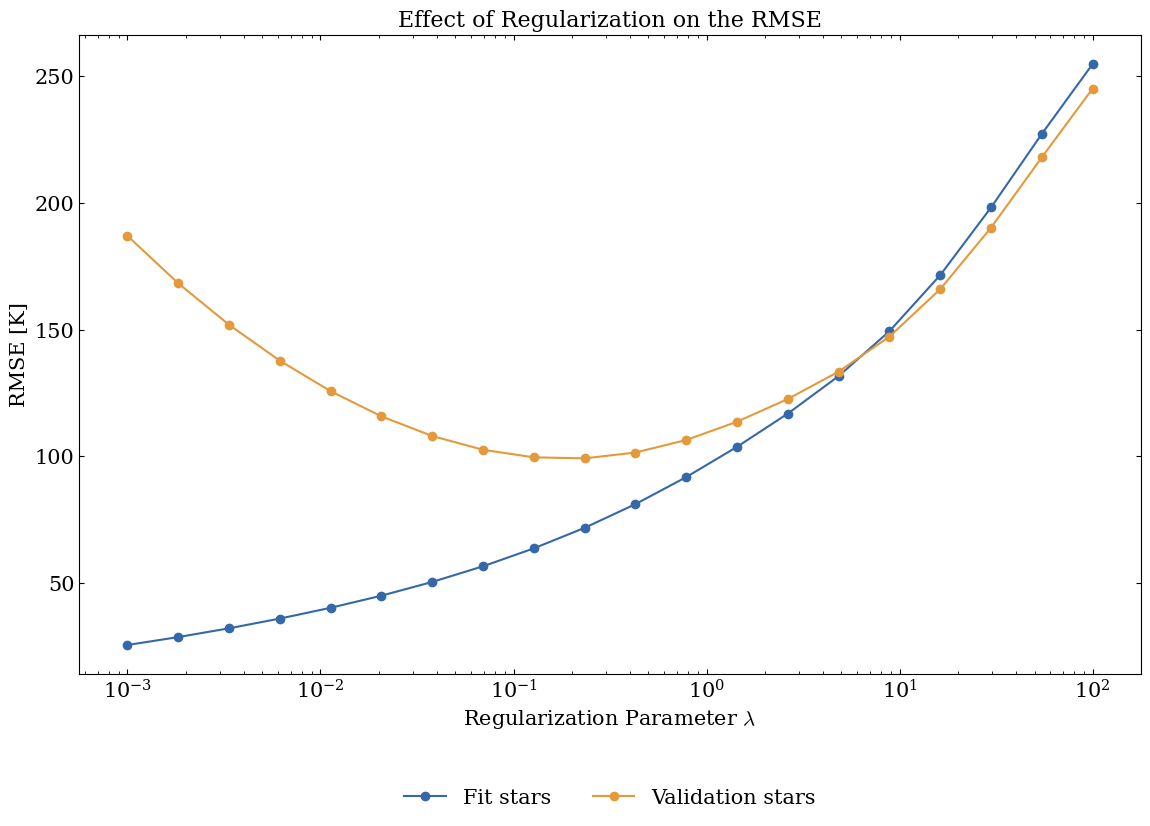

Optimal regularization parameter λ = 0.234
Validation RMSE with optimal λ = 99.2 K


In [8]:
# Convert to arrays for plotting
results_array = np.array([(r['lambda'], r['fit_rmse'], r['val_rmse'])
                          for r in results])

# Plot the regularization path
plt.figure(figsize=(13.7, 8.3))
plt.semilogx(results_array[:, 0], results_array[:, 1], '-o', color='C0', label='Fit stars')
plt.semilogx(results_array[:, 0], results_array[:, 2], '-o', color='C1', label='Validation stars')
plt.xlabel(r'Regularization Parameter $\lambda$')
plt.ylabel('RMSE [K]')
plt.title('Effect of Regularization on the RMSE')
plt.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.15))
plt.show()

# Find the optimal lambda, the one with the lowest validation RMSE
best_idx = np.argmin(results_array[:, 2])
best_lambda = results_array[best_idx, 0]
best_val_rmse = results_array[best_idx, 2]

print(f"Optimal regularization parameter λ = {best_lambda:.3f}")
print(f"Validation RMSE with optimal λ = {best_val_rmse:.1f} K")

The plot of the RMSE against $\lambda$ shows the bias-variance tradeoff (Section 4.7 of the textbook). It has three regimes.

1. **Low $\lambda$.** The model overfits. The RMSE is low on the fit stars and high on the validation stars.
2. **Best $\lambda$, about 0.2.** The validation RMSE is lowest, so the model generalizes best.
3. **High $\lambda$.** The constraints are too strong, and the model underfits. The RMSE is high on both groups, because the model cannot learn even the real relations in the data.

The validation RMSE only selects $\lambda$. We now refit the model on all training stars with the best $\lambda$ and compute the test RMSE once.

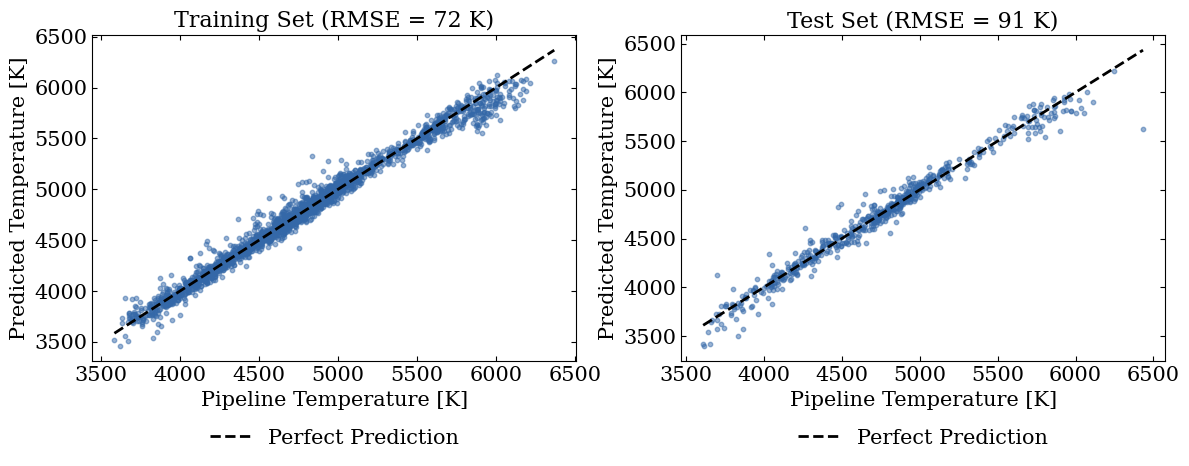

Model comparison
Unregularized, training = 28.7 K, test = 279.5 K
Regularized, training = 72.0 K, test = 91.0 K


In [9]:
# Compute the weights with the optimal regularization on all training stars
w_optimal = compute_regularized_weights(Phi_train, t_train, best_lambda)

# Make predictions with the optimal model
t_pred_train_opt = Phi_train @ w_optimal
t_pred_test_opt = Phi_test @ w_optimal

# Calculate the RMSE of the optimal model, with one evaluation on the test stars
train_rmse_opt = np.sqrt(np.mean((t_train - t_pred_train_opt)**2))
test_rmse_opt = np.sqrt(np.mean((t_test - t_pred_test_opt)**2))

# Visualize the predictions
plt.figure(figsize=(12, 5))

# Training set
plt.subplot(1, 2, 1)
plt.scatter(t_train, t_pred_train_opt, alpha=0.5, s=10)
plt.plot([t_train.min(), t_train.max()], [t_train.min(), t_train.max()],
         'k--', lw=2, label='Perfect Prediction')
plt.xlabel('Pipeline Temperature [K]')
plt.ylabel('Predicted Temperature [K]')
plt.title(f'Training Set (RMSE = {train_rmse_opt:.0f} K)')
plt.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.15))

# Test set
plt.subplot(1, 2, 2)
plt.scatter(t_test, t_pred_test_opt, alpha=0.5, s=10)
plt.plot([t_test.min(), t_test.max()], [t_test.min(), t_test.max()],
         'k--', lw=2, label='Perfect Prediction')
plt.xlabel('Pipeline Temperature [K]')
plt.ylabel('Predicted Temperature [K]')
plt.title(f'Test Set (RMSE = {test_rmse_opt:.0f} K)')
plt.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.15))

plt.tight_layout()
plt.show()

# Print the comparison
print("Model comparison")
print(f"Unregularized, training = {train_rmse_ml:.1f} K, test = {test_rmse_ml:.1f} K")
print(f"Regularized, training = {train_rmse_opt:.1f} K, test = {test_rmse_opt:.1f} K")

The regularized model generalizes much better. The test RMSE falls from about 280 K to about 90 K, which turns an unusable model into a useful one. The penalty keeps the weights from growing too large, so the model follows the noise of the training stars less.

The test predictions lie much closer to the diagonal than before, so the model has learned a real relation between the spectra and the temperature. The training and test RMSE are now close, which indicates good generalization. The stars hotter than 6000 K mostly lie below the diagonal, so the model under-predicts them. The penalty pulls the predictions toward the average temperature. Noise in the inputs, which we neglect here, flattens the relation in a similar way. This effect is called attenuation bias, and a later chapter treats it.

## Feature Engineering

Our regularized linear model works well, but so far it assumes a linear relation between the temperature and the spectral flux. This assumption may be too restrictive, because the physics of stellar atmospheres often gives nonlinear relations between the spectra and the stellar parameters.

We can model nonlinear relations and keep the analytical solution if we transform the input features with basis functions. The relation is then nonlinear in the original features, and the problem stays linear in the transformed features.

A simple extension adds quadratic terms. For each pixel with flux $\phi_j$, we add the feature $\phi_j^2$. The model can then learn that the temperature depends on the square of the flux as well as on the flux. This can describe the saturation of strong absorption lines, whose depth grows more slowly than the number of absorbing atoms. It can also describe a nonlinear sensitivity to the temperature.

The extension raises the number of features from 2,001 to 4,001 (2,000 linear features, 2,000 quadratic features and the bias). Overfitting becomes more likely, so regularization matters even more.

In [10]:
def create_quadratic_features(Phi):
    """Append the squared features to the design matrix. The bias column is not squared."""

    # Separate the features and the bias
    features = Phi[:, :-1]  # All columns except the last (bias)
    bias = Phi[:, -1:]      # The last column (bias)

    # Create the quadratic features
    features_squared = features ** 2

    # Combine as [features, features_squared, bias]
    Phi_quad = np.hstack([features, features_squared, bias])

    return Phi_quad

# Create the quadratic features for the training and test sets
Phi_train_quad = create_quadratic_features(Phi_train)
Phi_test_quad = create_quadratic_features(Phi_test)

print(f"Original feature dimensions = {Phi_train.shape[1]}")
print(f"Quadratic feature dimensions = {Phi_train_quad.shape[1]}")
print(f"Feature expansion = {Phi_train.shape[1]} → {Phi_train_quad.shape[1]}")

# First, try without regularization to see what happens
# The matrix Phi^T Phi is singular (4,001 weights for 2,400 stars), so np.linalg.inv gives no valid result
# np.linalg.lstsq returns the solution of smallest norm instead
print("\nTesting quadratic features without regularization...")
w_quad_unreg = np.linalg.lstsq(Phi_train_quad, t_train, rcond=None)[0]
t_pred_train_quad_unreg = Phi_train_quad @ w_quad_unreg
t_pred_test_quad_unreg = Phi_test_quad @ w_quad_unreg

train_rmse_quad_unreg = np.sqrt(np.mean((t_train - t_pred_train_quad_unreg)**2))
test_rmse_quad_unreg = np.sqrt(np.mean((t_test - t_pred_test_quad_unreg)**2))

print("Quadratic model (no regularization)")
print(f"Training RMSE = {train_rmse_quad_unreg:.1f} K")
print(f"Test RMSE = {test_rmse_quad_unreg:.1f} K")

Original feature dimensions = 2001
Quadratic feature dimensions = 4001
Feature expansion = 2001 → 4001

Testing quadratic features without regularization...
Quadratic model (no regularization)
Training RMSE = 0.0 K
Test RMSE = 247.7 K


The quadratic model has more weights than training stars, so it needs regularization. Without it, the fit passes through every training star, so the training RMSE is zero. We choose $\lambda$ for the expanded features on the validation stars as before, and we compute the test RMSE once.

In [11]:
# Create the quadratic features for the fit and validation stars
Phi_fit_quad = create_quadratic_features(Phi_fit)
Phi_val_quad = create_quadratic_features(Phi_val)

# Search for the optimal lambda with quadratic features, fitting the fit stars only
lambda_values_quad = np.logspace(-3, 2, 20)
results_quad = []

for lambda_reg in lambda_values_quad:
    # Compute the regularized weights for the quadratic features
    w_reg_quad = compute_regularized_weights(Phi_fit_quad, t_fit, lambda_reg)

    # Compute the predictions
    t_pred_fit_quad = Phi_fit_quad @ w_reg_quad
    t_pred_val_quad = Phi_val_quad @ w_reg_quad

    # Compute the RMSE
    fit_rmse_quad = np.sqrt(np.mean((t_fit - t_pred_fit_quad)**2))
    val_rmse_quad = np.sqrt(np.mean((t_val - t_pred_val_quad)**2))

    results_quad.append({
        'lambda': lambda_reg,
        'fit_rmse': fit_rmse_quad,
        'val_rmse': val_rmse_quad
    })

# Convert to an array for analysis
results_quad_array = np.array([(r['lambda'], r['fit_rmse'], r['val_rmse'])
                               for r in results_quad])

# Find the optimal lambda for the quadratic model, the one with the lowest validation RMSE
best_idx_quad = np.argmin(results_quad_array[:, 2])
best_lambda_quad = results_quad_array[best_idx_quad, 0]

# Refit on all training stars and evaluate once on the test stars
w_quad = compute_regularized_weights(Phi_train_quad, t_train, best_lambda_quad)
test_rmse_quad = np.sqrt(np.mean((t_test - Phi_test_quad @ w_quad)**2))

print(f"Optimal λ for quadratic features = {best_lambda_quad:.3f}")
print(f"Test RMSE with quadratic features = {test_rmse_quad:.1f} K")
print("\nComparison")
print(f"Linear features = {test_rmse_opt:.1f} K")
print(f"Quadratic features = {test_rmse_quad:.1f} K")

Optimal λ for quadratic features = 0.785
Test RMSE with quadratic features = 85.5 K

Comparison
Linear features = 91.0 K
Quadratic features = 85.5 K


The small improvement from the quadratic features gives three lessons.

1. **Small gain from more features.** Here doubling the number of features lowers the test RMSE by only a few percent. This suggests that the linear relations between the spectra and the temperature already carry most of the predictable signal.
2. **Regularization matters more.** The quadratic model needs a stronger regularization, a larger $\lambda$, than the linear model. This is expected, because more features make overfitting more likely.
3. **Domain knowledge matters.** Instead of adding polynomial features blindly, we can use astrophysical knowledge. Examples are the ratio of two absorption lines that depend differently on the temperature, and spectral regions that correlate with the stellar parameters.

This example shows a basic principle of machine learning. A more complex model is not always better. The regularized linear model is simpler and cheaper to compute, and its test RMSE is close to that of the quadratic model. In practice, the choice between simple and complex features depends on whether the small gain justifies a more complex model for the application.

## Summary

This tutorial showed the strengths and the limits of linear regression in an astronomical application. With real APOGEE spectra we studied concepts that apply far beyond this problem.

1. **Maximum likelihood estimation.** We implemented the analytical solution of linear regression, which follows from maximizing the Gaussian likelihood. The closed-form solution $\mathbf{w}_{\text{ML}} = (\boldsymbol{\Phi}^T \boldsymbol{\Phi})^{-1} \boldsymbol{\Phi}^T \mathbf{t}$ gives the global optimum, which we do not have for more complex models.
2. **Overfitting.** The first model had a training RMSE of about 30 K and a test RMSE of about 280 K. This shows why every machine learning application needs an evaluation on test stars.
3. **Regularization.** A penalty on the weights turned this unusable model into one with a test RMSE of about 90 K. The regularization parameter $\lambda$ sets the bias-variance tradeoff, and we chose it on validation stars. A Bayesian prior has the same kind of hyperparameter, its width, and it also needs validation stars.
4. **Feature engineering.** The quadratic features gave only a small improvement here. This does not make feature engineering unimportant. For other stellar parameters or a wider parameter range, nonlinear features may be needed. The data and the validation error should decide how complex the model is.

The principles of this tutorial are maximum likelihood estimation, regularization and feature engineering. They are the basis of more sophisticated methods, such as Bayesian approaches, nonlinear models and deep learning. The basic problem stays the same, which is to extract useful relations from data and to avoid overfitting.